In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import plot_tree

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [112]:
df = pd.read_csv("/Users/aryasrivastava23/Documents/Stress Indicators Dataset for Mental Health Classification.csv")

print("Shape of dataset:", df.shape)

df.head(10)

Shape of dataset: (2000, 26)


,gender,age,stress_experience,heartbeat_palpitations,anxiety_tension,sleep_problems,restlessness,headaches,irritability,concentration_problems,...,professor_difficulties,work_environment,lack_relaxation_time,home_environment,low_academic_confidence,subject_confidence,academic_conflicts,class_attendance,weight_changes,stress_type
0,1,20,1,2,2,4,3,1,4,5,...,2,3,1,1,4,1,1,3,2,1
1,0,19,4,5,5,4,4,5,4,5,...,2,4,4,5,5,5,5,3,5,0
2,0,21,4,2,3,3,4,4,1,3,...,2,3,3,3,3,3,4,4,2,1
3,0,20,1,3,2,1,3,1,5,5,...,1,3,3,1,3,5,4,2,3,1
4,0,19,4,3,3,2,3,4,2,3,...,3,2,4,2,2,2,3,4,4,1
5,0,19,2,3,2,3,4,1,1,1,...,1,3,5,4,4,1,5,3,1,1
6,0,18,1,1,1,4,3,3,1,3,...,2,3,4,2,1,1,1,1,1,1
7,0,19,1,1,4,1,2,3,2,3,...,3,2,1,1,1,1,1,1,1,1
8,0,21,3,3,4,3,2,2,3,5,...,3,1,3,3,4,3,4,5,3,1
9,0,19,3,2,3,2,3,3,4,5,...,5,5,5,4,5,5,4,4,1,1


In [88]:
#DEScriptive
df.tail(5)
df.info()

print("\nStatistical summary:")
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   gender                   2000 non-null   int64
 1   age                      2000 non-null   int64
 2   stress_experience        2000 non-null   int64
 3   heartbeat_palpitations   2000 non-null   int64
 4   anxiety_tension          2000 non-null   int64
 5   sleep_problems           2000 non-null   int64
 6   restlessness             2000 non-null   int64
 7   headaches                2000 non-null   int64
 8   irritability             2000 non-null   int64
 9   concentration_problems   2000 non-null   int64
 10  sadness_low_mood         2000 non-null   int64
 11  health_issues            2000 non-null   int64
 12  loneliness_isolation     2000 non-null   int64
 13  academic_overload        2000 non-null   int64
 14  peer_competition         2000 non-null   int64
 15  relationship_st

,gender,age,stress_experience,heartbeat_palpitations,anxiety_tension,sleep_problems,restlessness,headaches,irritability,concentration_problems,...,professor_difficulties,work_environment,lack_relaxation_time,home_environment,low_academic_confidence,subject_confidence,academic_conflicts,class_attendance,weight_changes,stress_type
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.354000,20.007500,2.975000,2.739500,2.532000,2.767000,2.660500,2.617000,2.701500,2.695000,...,2.453000,2.485500,2.518000,2.418500,2.568000,2.615500,2.740500,3.255000,2.396500,1.016000
std,0.478329,4.776385,1.127391,1.104649,1.201956,1.257578,1.284159,1.256225,1.321844,1.314473,...,1.196874,1.195619,1.246777,1.251855,1.283043,1.290927,1.263708,1.202788,1.111713,0.292894
min,0.000000,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,19.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,1.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000,1.000000
50%,0.000000,19.000000,3.000000,3.000000,2.000000,3.000000,2.000000,2.000000,3.000000,3.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,2.000000,1.000000
75%,1.000000,20.000000,4.000000,4.000000,3.000000,4.000000,4.000000,3.250000,4.000000,4.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,3.000000,1.000000
max,1.000000,100.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,2.000000


In [89]:
print("\nMissing values in each column:")
print(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())


Missing values in each column:
gender                     0
age                        0
stress_experience          0
heartbeat_palpitations     0
anxiety_tension            0
sleep_problems             0
restlessness               0
headaches                  0
irritability               0
concentration_problems     0
sadness_low_mood           0
health_issues              0
loneliness_isolation       0
academic_overload          0
peer_competition           0
relationship_stress        0
professor_difficulties     0
work_environment           0
lack_relaxation_time       0
home_environment           0
low_academic_confidence    0
subject_confidence         0
academic_conflicts         0
class_attendance           0
weight_changes             0
stress_type                0
dtype: int64
Number of duplicate rows: 1191


In [90]:
print("\\nOriginal target class counts:")
print(df["stress_type"].value_counts().sort_index())


\nOriginal target class counts:
stress_type
0      70
1    1828
2     102
Name: count, dtype: int64


In [91]:
#possible outliers
print("\\nSkewness of numeric columns:")
print(df.select_dtypes(include=np.number).skew().sort_values(ascending=False).to_frame("Skewness"))

\nSkewness of numeric columns:
                          Skewness
age                      12.487733
gender                    0.611070
home_environment          0.585862
weight_changes            0.563295
peer_competition          0.549945
professor_difficulties    0.538702
stress_type               0.473526
work_environment          0.465862
relationship_stress       0.462535
lack_relaxation_time      0.445751
loneliness_isolation      0.439240
sadness_low_mood          0.414647
low_academic_confidence   0.399259
anxiety_tension           0.387485
subject_confidence        0.382983
health_issues             0.378395
academic_overload         0.369909
headaches                 0.357929
restlessness              0.321290
concentration_problems    0.273197
academic_conflicts        0.262813
irritability              0.229818
heartbeat_palpitations    0.229081
sleep_problems            0.211275
stress_experience         0.084775
class_attendance         -0.302598


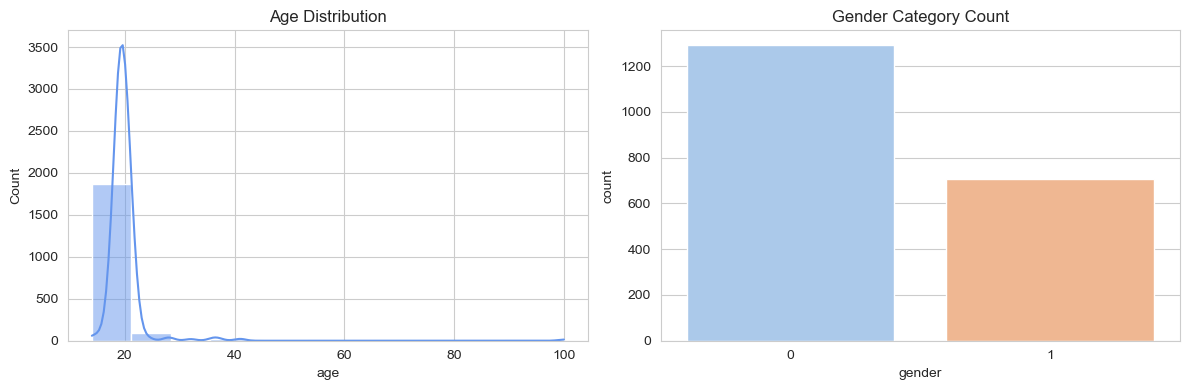

In [92]:
#AGE DISTRIBUTION AND GENDER CATEGORY COUNT
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='age', bins=12, kde=True, color='cornflowerblue', ax=axes[0])
axes[0].set_title('Age Distribution')
sns.countplot(data=df, x='gender', hue='gender', palette='pastel', legend=False, ax=axes[1])
axes[1].set_title('Gender Category Count')
plt.tight_layout()
plt.show()

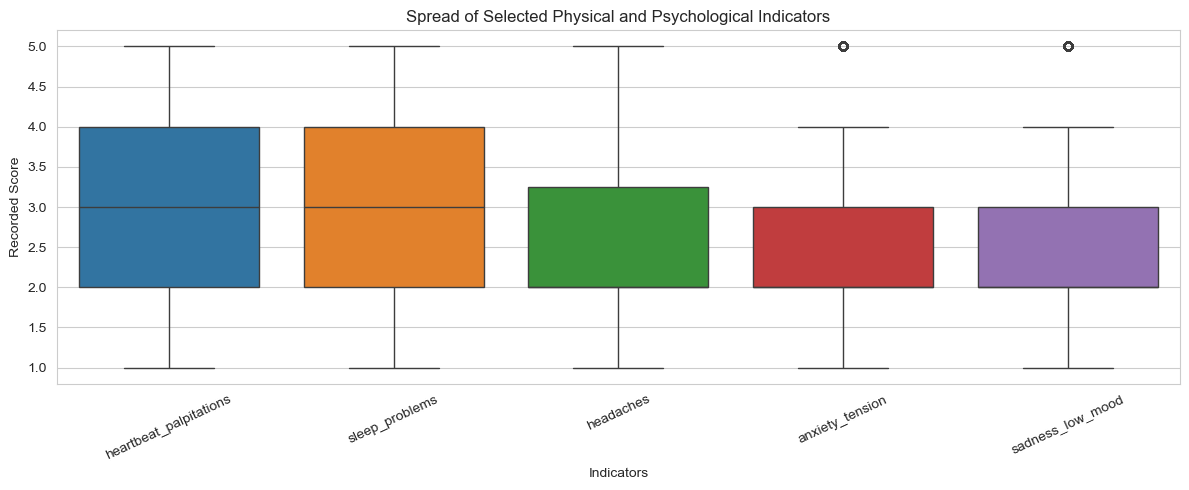

In [93]:
#Spread of Selected Physical and Psychological Indicators
selected_indicators = [
    "heartbeat_palpitations", "sleep_problems",
    "headaches", "anxiety_tension", "sadness_low_mood"
]

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[selected_indicators])
plt.title("Spread of Selected Physical and Psychological Indicators")
plt.xlabel("Indicators")
plt.ylabel("Recorded Score")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

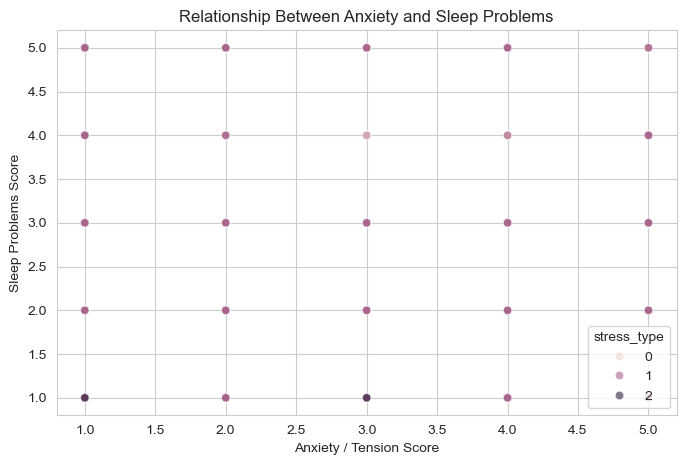

In [94]:
#Relationship Between Anxiety and Sleep Problems
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="anxiety_tension",
    y="sleep_problems",
    hue="stress_type",
    alpha=0.6
)
plt.title("Relationship Between Anxiety and Sleep Problems")
plt.xlabel("Anxiety / Tension Score")
plt.ylabel("Sleep Problems Score")
plt.show()

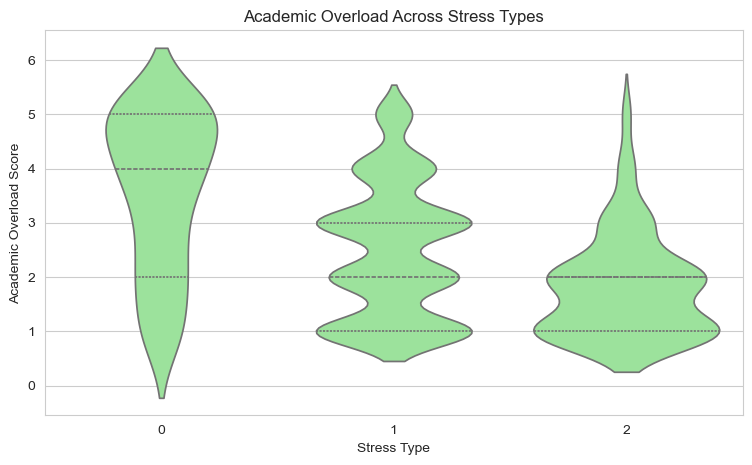

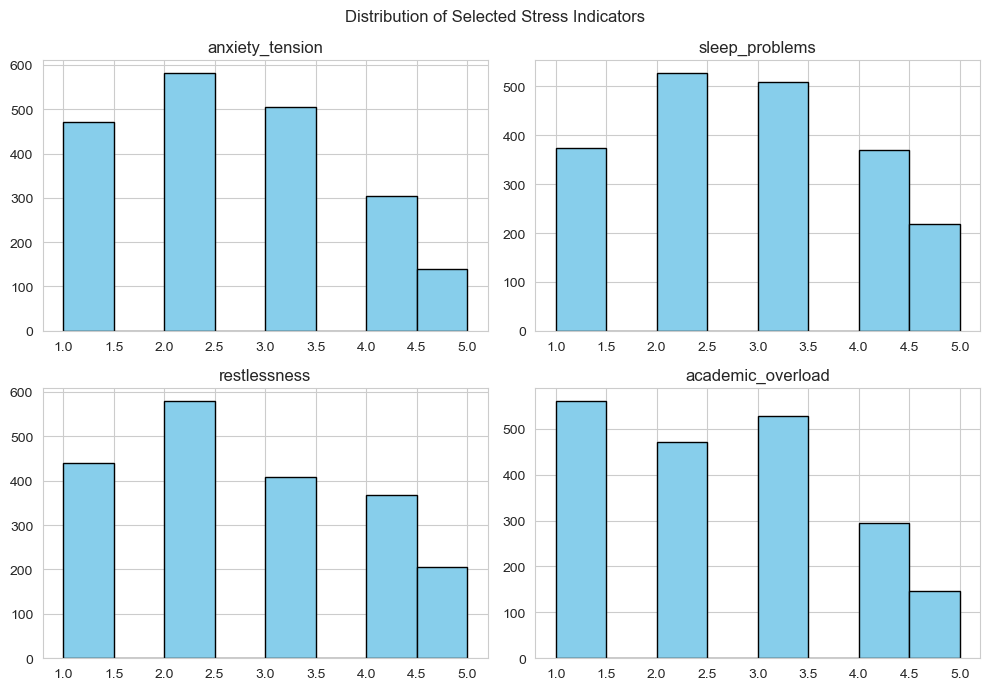

In [95]:
#Academic Overload Across Stress Types
plt.figure(figsize=(9, 5))
sns.violinplot(
    data=df,
    x="stress_type",
    y="academic_overload",
    inner="quartile",
    color="lightgreen"
)
plt.title("Academic Overload Across Stress Types")
plt.xlabel("Stress Type")
plt.ylabel("Academic Overload Score")
plt.show()

selected_features = ['anxiety_tension', 'sleep_problems', 'restlessness', 'academic_overload']
df[selected_features].hist(figsize=(10, 7), bins=8, color='skyblue', edgecolor='black')
plt.suptitle('Distribution of Selected Stress Indicators')
plt.tight_layout()
plt.show()

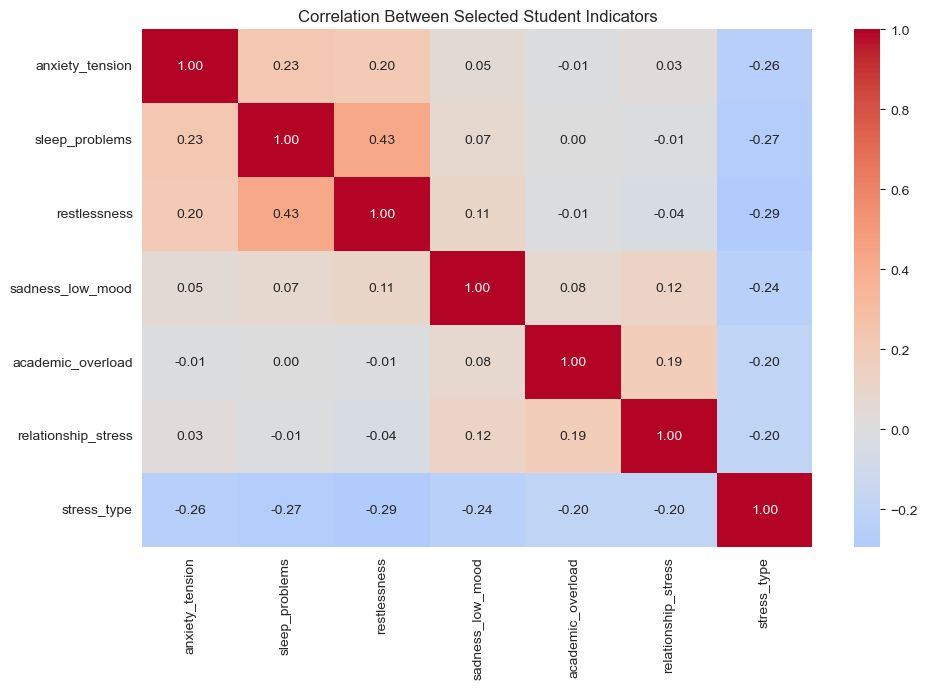

In [96]:
#CORRELATION HEATMAP
relationship_columns = [
    "anxiety_tension", "sleep_problems", "restlessness",
    "sadness_low_mood", "academic_overload",
    "relationship_stress", "stress_type"
]

relationship_corr = df[relationship_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(relationship_corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Between Selected Student Indicators")
plt.tight_layout()
plt.show()

In [97]:
#Preprocessing for Classification
#Inferential
target = "stress_type"

X = df.drop(columns=[target, "stress_experience"])
y = df[target]

# Fill missing numeric values 
X = X.fillna(X.median(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
s = StandardScaler()

X_train_scaled = s.fit_transform(X_train)
X_test_scaled = s.transform(X_test)



/Users/aryasrivastava23/miniforge3/envs/datascience/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion confusion_matrix: 
[[ 12   1   0]
 [  0 371   0]
 [  0   3  13]]

Accuracy: 0.99


/Users/aryasrivastava23/miniforge3/envs/datascience/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


<Figure size 900x600 with 0 Axes>

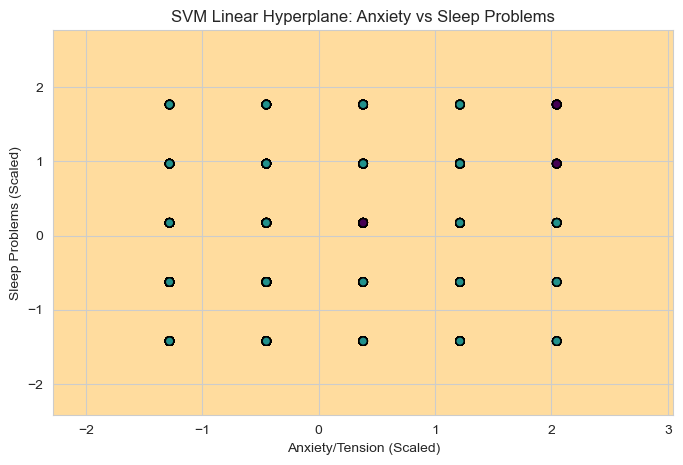

In [121]:
#CLASSIFIER IMPLEMENTATION
# 1. Support Vector Machine
svm_model = SVC(kernel="rbf", probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_pred = svm_model.predict(X_test_scaled)

cm = confusion_matrix(y_test,svm_pred)
svm_acc = accuracy_score(y_test,svm_pred)
print("\nConfusion confusion_matrix: ")
print(cm)
print("\nAccuracy:", svm_acc)

# Select two variables only for the 2-D visualisation
visual_features = ["anxiety_tension", "sleep_problems"]

X_train_two = X_train[visual_features]
X_test_two = X_test[visual_features]

# Scale the two selected variables
visual_scaler = StandardScaler()
X_train_two_scaled = visual_scaler.fit_transform(X_train_two)

# Train a simple SVM model for this graph


# SVM Linear Hyperplane

svm_visual = SVC(kernel='linear', C=100)
svm_visual.fit(X_train_two_scaled, y_train)

plt.figure(figsize=(9, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_visual,
    X_train_two_scaled,
    response_method='predict',
    cmap='coolwarm',
    alpha=0.4
)

plt.scatter(
    X_train_two_scaled[:, 0],
    X_train_two_scaled[:, 1],
    c=y_train,
    cmap='viridis',
    edgecolors='black'
)

plt.title("SVM Linear Hyperplane: Anxiety vs Sleep Problems")
plt.xlabel("Anxiety/Tension (Scaled)")
plt.ylabel("Sleep Problems (Scaled)")
plt.show()

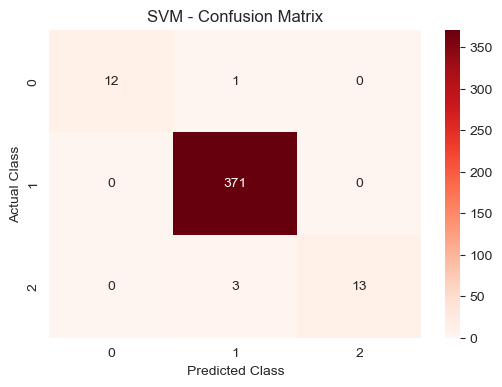

In [99]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Reds')
plt.title('SVM - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [114]:
# 2. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
nb_pred = nb_model.predict(X_test_scaled)

cm_nb = confusion_matrix(y_test, nb_pred)
acc_nb = accuracy_score(y_test, nb_pred)
print("\nNaive Bayes Confusion Matrix:")
print(cm_nb)
print("\nNaive Bayes Accuracy:", acc_nb)







Naive Bayes Confusion Matrix:
[[ 11   2   0]
 [  5 355  11]
 [  0   4  12]]

Naive Bayes Accuracy: 0.945


/Users/aryasrivastava23/miniforge3/envs/datascience/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


<Figure size 900x600 with 0 Axes>

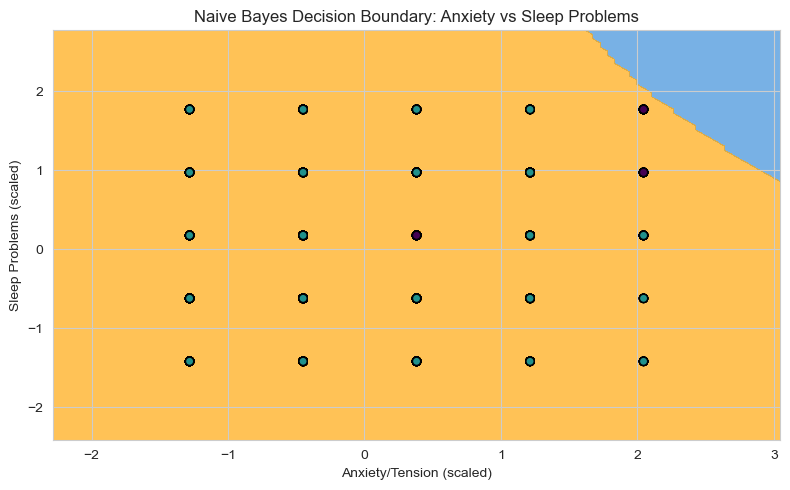

In [120]:
# Naive Bayes Decision Boundary

nb_visual = GaussianNB()
nb_visual.fit(X_train_two_scaled, y_train)

plt.figure(figsize=(9, 6))

DecisionBoundaryDisplay.from_estimator(
    nb_visual,
    X_train_two_scaled,
    response_method="predict",
    cmap="Pastel2",
    alpha=0.7
)

plt.scatter(
    X_train_two_scaled[:, 0],
    X_train_two_scaled[:, 1],
    c=y_train,
    cmap="viridis",
    edgecolors="black",
    s=35
)

plt.title("Naive Bayes Decision Boundary: Anxiety vs Sleep Problems")
plt.xlabel("Anxiety/Tension (scaled)")
plt.ylabel("Sleep Problems (scaled)")
plt.tight_layout()
plt.show()

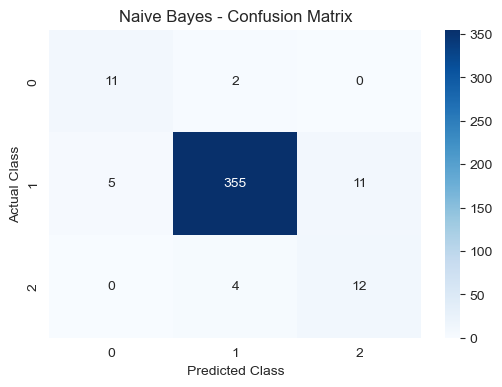

<Figure size 800x500 with 0 Axes>

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, nb_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()



K-Nearest Neighbors Confusion Matrix:
[[  8   5   0]
 [  0 361  10]
 [  0   6  10]]

K-Nearest Neighbors Accuracy: 0.9475


/Users/aryasrivastava23/miniforge3/envs/datascience/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


<Figure size 900x600 with 0 Axes>

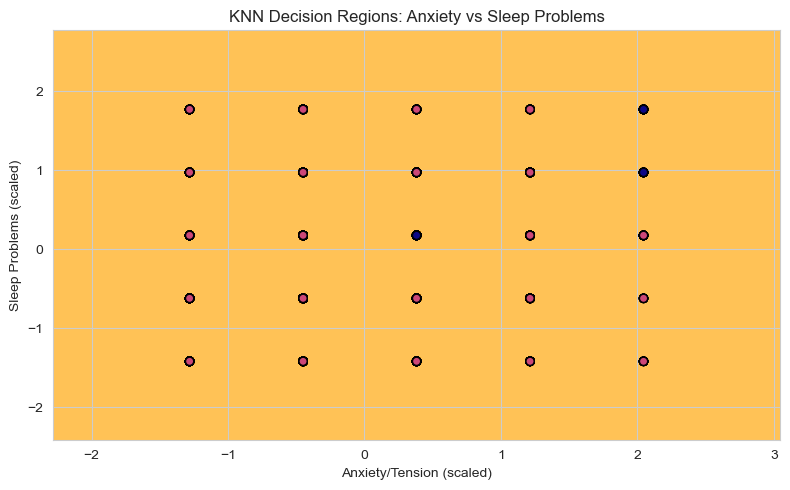

In [102]:
# 3. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

cm_knn = confusion_matrix(y_test, knn_pred)
acc_knn = accuracy_score(y_test, knn_pred)
print("\nK-Nearest Neighbors Confusion Matrix:")
print(cm_knn)
print("\nK-Nearest Neighbors Accuracy:", acc_knn)

# Train a simple KNN model on the same two variables for visualisation
knn_visual = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn_visual.fit(X_train_two_scaled, y_train)

plt.figure(figsize=(9, 6))
DecisionBoundaryDisplay.from_estimator(
    knn_visual,
    X_train_two_scaled,
    response_method="predict",
    cmap="Pastel2",
    alpha=0.7
)
plt.scatter(
    X_train_two_scaled[:, 0],
    X_train_two_scaled[:, 1],
    c=y_train,
    cmap="plasma",
    edgecolors="black",
    s=35
)
plt.title("KNN Decision Regions: Anxiety vs Sleep Problems")
plt.xlabel("Anxiety/Tension (scaled)")
plt.ylabel("Sleep Problems (scaled)")
plt.tight_layout()
plt.show()


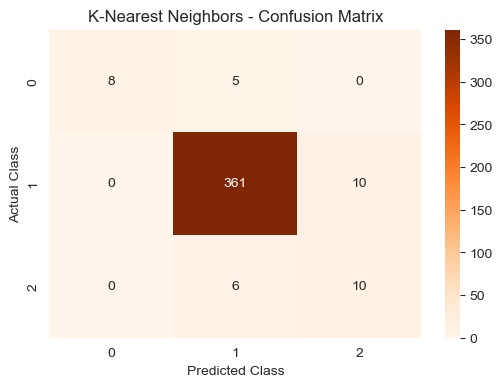

In [103]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d', cmap='Oranges')
plt.title('K-Nearest Neighbors - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()


Confusion Matrix: [[ 12   1   0]
 [  0 371   0]
 [  0   1  15]]
Accuracy: 0.995


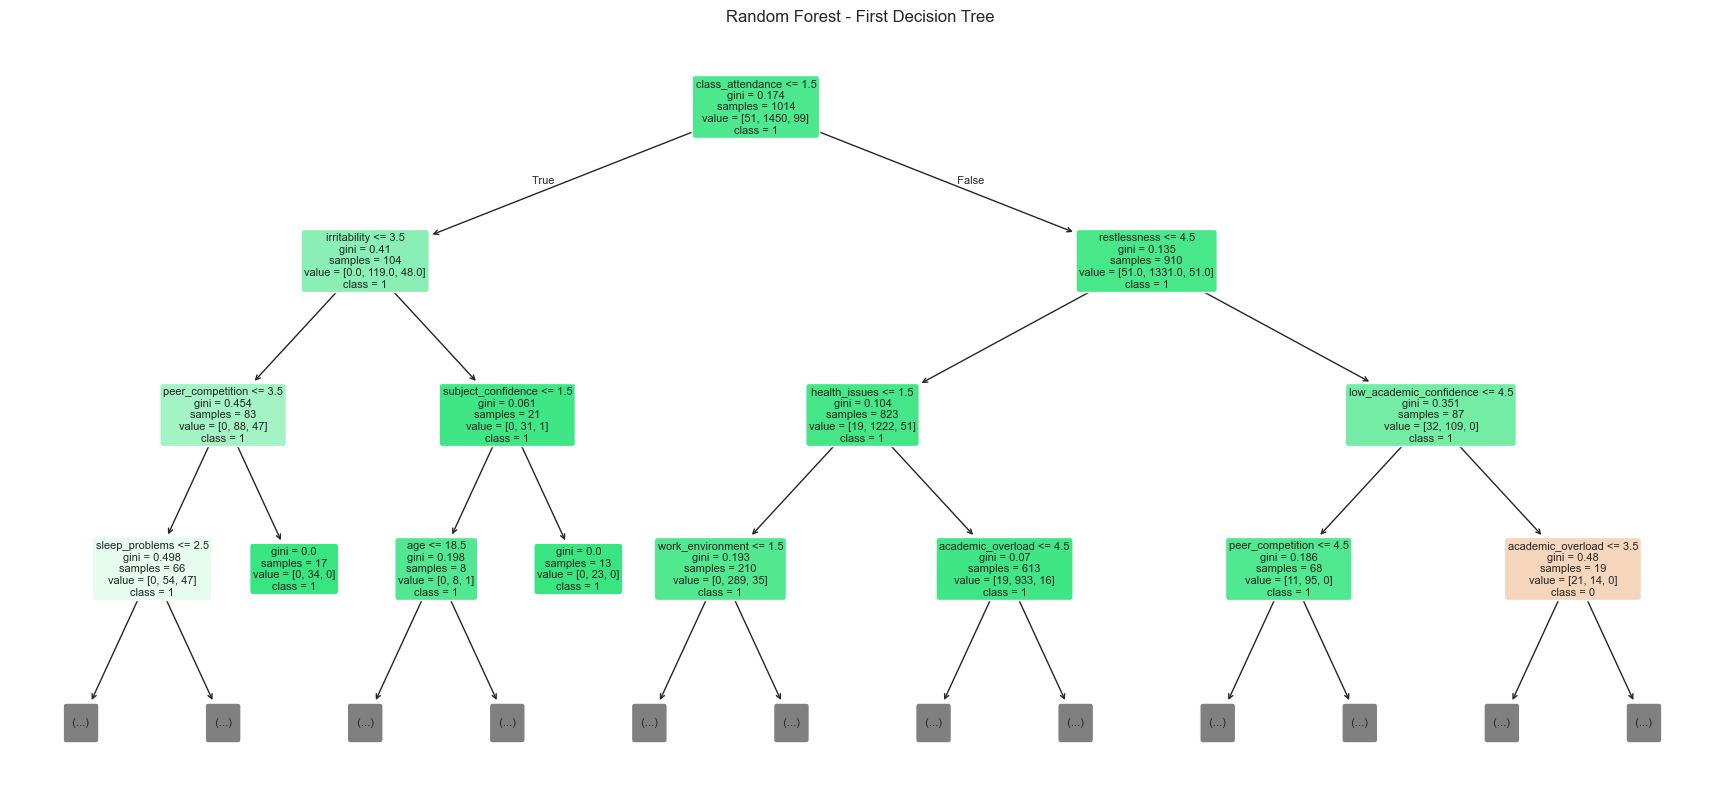

In [104]:
# 4. Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

cm = confusion_matrix(y_test, rf_pred)
print("Confusion Matrix:",cm)
acc = accuracy_score(y_test, rf_pred)
print("Accuracy:", acc)

#RANDOM FOREST DIAGRAM
# Display the first tree from the trained Random Forest
plt.figure(figsize=(22, 10))
plot_tree(
    rf_model.estimators_[0],
    feature_names=X.columns,
    class_names=[str(c) for c in rf_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title('Random Forest - First Decision Tree ')
plt.show()


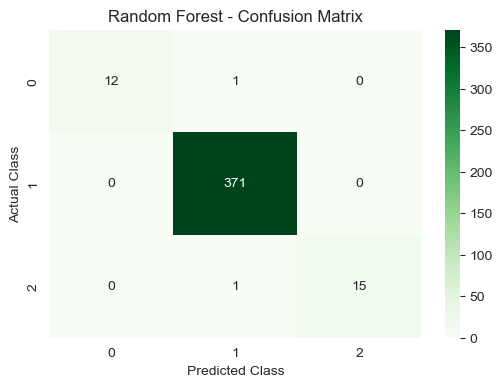

In [105]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Greens')
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [106]:
#IDENTIFY THE BEST MODEL BASED ON ACCURACY
results = pd.DataFrame({
    'Classifier': ['SVM', 'Naive Bayes', 'KNN', 'Random Forest'],
    'Accuracy': [svm_acc, acc_nb, acc_knn, acc]
})
results['Accuracy (%)'] = (results['Accuracy'] * 100).round(2)
display(results[['Classifier', 'Accuracy (%)']].sort_values('Accuracy (%)', ascending=False))       
                                                                                    




,Classifier,Accuracy (%)
3,Random Forest,99.50
0,SVM,99.00
2,KNN,94.75
1,Naive Bayes,94.50


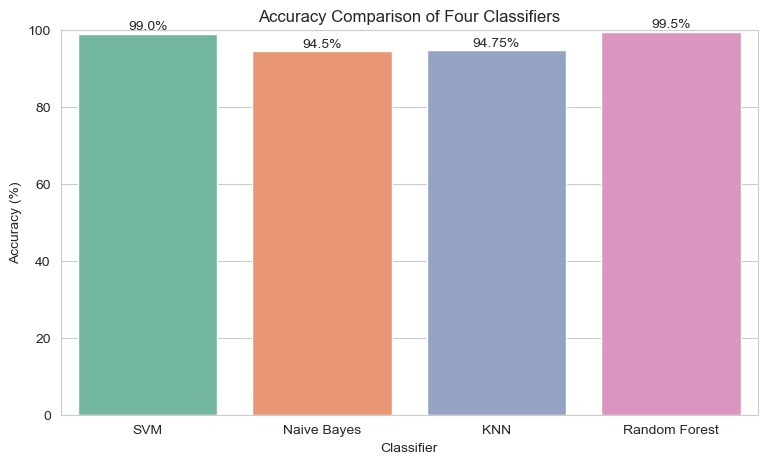

In [107]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results, x='Classifier', y='Accuracy (%)', hue='Classifier', palette='Set2', legend=False)
plt.title('Accuracy Comparison of Four Classifiers')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
for i, value in enumerate(results['Accuracy (%)']):
    plt.text(i, value + 1, str(value) + '%', ha='center')
plt.show()

In [108]:
# As required for this project, the best-fit model is selected using accuracy only.
best_accuracy = results['Accuracy'].max()
best_models = results.loc[results['Accuracy'] == best_accuracy, 'Classifier'].tolist()
print('Highest accuracy:', round(best_accuracy * 100, 2), '%')
print('Best-fit model(s) based on accuracy:', ', '.join(best_models))

Highest accuracy: 99.5 %
Best-fit model(s) based on accuracy: Random Forest
